# C4 Notebook 08 — Held-Out Evaluation and Ablation Evidence

In [1]:
from pathlib import Path
import numpy as np,pandas as pd,json
REPO_OVERRIDE=None
start=Path(REPO_OVERRIDE).resolve() if REPO_OVERRIDE else Path.cwd().resolve()
ROOT=next((p for p in (start,*start.parents) if (p/'c4_fusion/src').exists() and (p/'shared').exists()),None)
if ROOT is None: raise FileNotFoundError('Set REPO_OVERRIDE to repository root')
OUT=ROOT/'results/pp1/c4_neural'
all_models=['M1','M2','M3','M4','M5','M6','M7']

In [2]:
# Recompute metrics from saved predictions; reject inconsistent test rows
rows=[];frames={};ids_ref=None
for name in all_models:
    path=OUT/f'{name}_test_predictions.csv'
    if not path.is_file():
        print(name,'NOT TRAINED/NOT SAVED');continue
    df=pd.read_csv(path)
    assert len(df)==351 and df.record_id.is_unique
    assert df.split.eq('TEST').all()
    ids=set(df.record_id)
    if ids_ref is None:ids_ref=ids
    else:assert ids==ids_ref,f'{name} has different test records'
    for c in ['current_stage_m','target_stage_m','pred_stage_m']:
        assert np.isfinite(df[c]).all(),f'{name} has nonfinite values'
    # Sort on record_id so each model is compared in the same order.
    df=df.sort_values('record_id').reset_index(drop=True)
    if frames:
        x=next(iter(frames.values()))
        assert np.allclose(x.target_stage_m,df.target_stage_m,atol=1e-6)
        assert np.allclose(x.current_stage_m,df.current_stage_m,atol=1e-6)
    frames[name]=df
    e=df.pred_stage_m-df.target_stage_m
    rows.append({'model':name,'n':len(df),'mae_m':np.mean(abs(e)),'rmse_m':np.sqrt(np.mean(e*e))})
results=pd.DataFrame(rows)
if len(results):display(results)
else:print('No completed model test predictions yet.')

,model,n,mae_m,rmse_m
0,M1,351,0.214039,0.403648
1,M2,351,0.220114,0.399271
2,M3,351,0.213740,0.400947
3,M4,351,0.215715,0.404630
4,M5,351,0.216129,0.406008
5,M6,351,0.215910,0.400967
6,M7,351,0.215193,0.404004


In [3]:
# Persistence comparison and M7–M6 if BOTH models are available
if frames:
    df=next(iter(frames.values()))
    pe=df.current_stage_m-df.target_stage_m
    baseline={'model':'PERSISTENCE','n':len(df),'mae_m':float(np.abs(pe).mean()),'rmse_m':float(np.sqrt((pe*pe).mean()))}
    print('Persistence:',baseline)
    report=pd.concat([results,pd.DataFrame([baseline])],ignore_index=True)
    report.to_csv(OUT/'c4_all_models_vs_persistence.csv',index=False)
    if {'M7','M6'}.issubset(frames):
        mae=report.set_index('model')['mae_m'];print('M7 minus M6 MAE in metres:',float(mae['M7']-mae['M6']))
        print('Negative is better for M7; report the actual result even if positive.')

Persistence: {'model': 'PERSISTENCE', 'n': 351, 'mae_m': 0.2172298602696158, 'rmse_m': 0.4066135811718991}
M7 minus M6 MAE in metres: -0.0007170354496379705
Negative is better for M7; report the actual result even if positive.


In [4]:
# Gauge-level errors, not only station-day pooled errors
if frames:
    grouped=[]
    for name,df in frames.items():
        for st,group in df.groupby('station_id'):
            e=group.pred_stage_m-group.target_stage_m
            grouped.append({'model':name,'station_id':st,'n':len(group),
                'mae_m':float(np.abs(e).mean()),'rmse_m':float(np.sqrt(np.mean(e**2)))})
    station_metrics=pd.DataFrame(grouped)
    station_metrics.to_csv(OUT/'c4_station_level_test_metrics.csv',index=False)
    display(station_metrics.head(12))

,model,station_id,n,mae_m,rmse_m
0,M1,badalgama,9,0.090810,0.158600
1,M1,baddegama,9,0.186580,0.267720
2,M1,deraniyagala,9,0.077505,0.098704
3,M1,dunamale,9,0.074071,0.108617
4,M1,ellagawa,9,0.339376,0.460438
5,M1,galgamuwa,9,0.318166,0.448673
6,M1,giriulla,9,0.072581,0.110693
7,M1,glencourse,9,0.142137,0.172899
8,M1,hanwella,9,0.060462,0.094563
9,M1,holombuwa,9,0.047441,0.056883


## A — Why is training MAE higher? Compare stage-change distributions

This is **descriptive**: inspect the observed Δstage across the existing chronological train/validation/test partitions. Persistence requires no fitted model. Do not use the test period to choose new hyperparameters.

In [6]:
# A — Source-derived baseline difficulty by chronological split
BASE = ROOT/'data/processed/c4/aligned'
index_path=BASE/'c4_aligned_index_1429_PRIVATE.csv'
labels_path=BASE/'c4_aligned_labels_1429_PRIVATE.npz'
if not index_path.is_file() or not labels_path.is_file():
    raise FileNotFoundError('Missing the Notebook 06 aligned index/labels in data/processed/c4/aligned/')
aligned=pd.read_csv(index_path,encoding='utf-8-sig',low_memory=False).sort_values('array_row').reset_index(drop=True)
with np.load(labels_path,allow_pickle=False) as loaded:
    stage_delta=loaded['y_delta_stage_m'].reshape(-1).copy()
    source_ids=loaded['record_id'].astype(str).copy()
assert len(aligned)==1429 and np.array_equal(aligned['array_row'].to_numpy(),np.arange(1429))
assert np.array_equal(aligned.record_id.astype(str).to_numpy(),source_ids)
assert len(stage_delta)==1429 and np.isfinite(stage_delta).all()
aligned['observed_delta_m']=stage_delta
split_rows=[]
for label, grp in aligned.groupby('split'):
    d=grp.observed_delta_m.to_numpy()
    split_rows.append({'split':label,'n':len(d), 'persistence_mae_m':float(np.abs(d).mean()),
        'persistence_rmse_m':float(np.sqrt(np.mean(d*d))),
        'rises_ge_0p5m':int((d>=0.5).sum()),'falls_le_minus0p5m':int((d<=-0.5).sum()),
        'stable_abs_le_0p1m':int((np.abs(d)<=0.1).sum()),
        'median_delta_m':float(np.median(d)), 'p90_abs_delta_m':float(np.quantile(np.abs(d),.9))})
split_difficulty=pd.DataFrame(split_rows).set_index('split').loc[['TRAIN','VALIDATION','TEST']].reset_index()
assert split_difficulty.set_index('split')['n'].to_dict()=={'TRAIN':809,'VALIDATION':269,'TEST':351}
(split_difficulty).to_csv(OUT/'c4_split_difficulty.csv',index=False)
display(split_difficulty)
print('Interpretation: the target stage changes (and baseline difficulty) vary across chronological splits.')

,split,n,persistence_mae_m,persistence_rmse_m,rises_ge_0p5m,falls_le_minus0p5m,stable_abs_le_0p1m,median_delta_m,p90_abs_delta_m
0,TRAIN,809,0.665400,1.131857,162,139,221,-0.04,1.802
1,VALIDATION,269,0.234872,0.403574,17,19,125,-0.04,0.552
2,TEST,351,0.217230,0.406614,24,21,198,-0.03,0.630


Interpretation: the target stage changes (and baseline difficulty) vary across chronological splits.


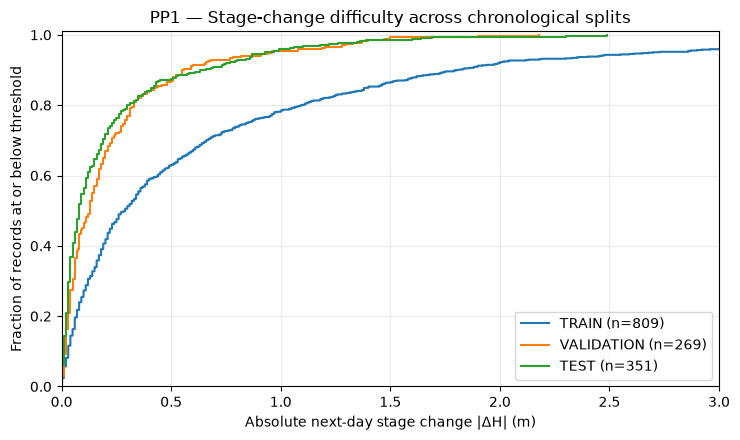

Note: chart zooms to 0–3 m. Larger changes are still included in saved metrics.


In [7]:
# Optional PP1 Figure A — empirical distributions of absolute next-day stage changes
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(7.5,4.5))
for split in ['TRAIN','VALIDATION','TEST']:
    values=np.sort(np.abs(aligned.loc[aligned.split==split,'observed_delta_m'].to_numpy()))
    probs=np.arange(1,len(values)+1)/len(values)
    ax.step(values,probs,where='post',label=f'{split} (n={len(values)})')
ax.set_xlim(0,3)  # readable view; original calculations include values larger than 3 m
ax.set_ylim(0,1.01)
ax.set_xlabel('Absolute next-day stage change |ΔH| (m)')
ax.set_ylabel('Fraction of records at or below threshold')
ax.set_title('PP1 — Stage-change difficulty across chronological splits')
ax.legend();ax.grid(alpha=0.25);fig.tight_layout()
fig.savefig(OUT/'c4_split_stage_change_ecdf.png',dpi=160)
plt.show()
print('Note: chart zooms to 0–3 m. Larger changes are still included in saved metrics.')

## B — Gauge-specific flood-status evaluation (official source-derived levels)

Using the **three thresholds belonging to each individual gauge** in the private DMC CSV: `alert_threshold_m`, `minor_flood_threshold_m` and `major_flood_threshold_m`. They are in **metres**, including conversion from feet for Nagalagam Street.

For **observed**, **predicted**, and **persistence-predicted** **Day T+1 stage** (`H_T+1`), apply exactly the same four exclusive categories:

- **NORMAL**: stage below alert threshold
- **ALERT**: alert ≤ stage < minor-flood threshold
- **MINOR FLOOD**: minor-flood ≤ stage < major-flood threshold
- **MAJOR FLOOD**: stage ≥ major-flood threshold

In [9]:
# B — Per-gauge source-derived flood thresholds; held-out test classifications and errors
PRIVATE_DMC = ROOT/'c4_fusion/private_data/observations/FloodRisk_DMC_StationDay_LABELLED_1429.csv'
PRIVATE_OUT = ROOT/'data/processed/c4/evaluation_private'
PRIVATE_OUT.mkdir(parents=True,exist_ok=True)
THRESHOLD_COLS=['alert_threshold_m','minor_flood_threshold_m','major_flood_threshold_m']
STATUS_ORDER=['NORMAL','ALERT','MINOR FLOOD','MAJOR FLOOD']

if not PRIVATE_DMC.is_file():
    raise FileNotFoundError(f'Expected PRIVATE source CSV: {PRIVATE_DMC}. Do not substitute a hard-coded shared threshold table.')
columns=['record_id','station_id','stage_at_issue_m','target_stage_next_day_m']+THRESHOLD_COLS
source=pd.read_csv(PRIVATE_DMC,encoding='utf-8-sig',usecols=columns,low_memory=False)
assert len(source)==1429 and source.record_id.is_unique
assert source.station_id.nunique()==39
for col in THRESHOLD_COLS+['stage_at_issue_m','target_stage_next_day_m']:
    source[col]=pd.to_numeric(source[col],errors='raise')
assert np.isfinite(source[THRESHOLD_COLS].to_numpy()).all()
assert ((source.alert_threshold_m<source.minor_flood_threshold_m)&
        (source.minor_flood_threshold_m<source.major_flood_threshold_m)).all()
assert (source.groupby('station_id')[THRESHOLD_COLS].nunique()==1).all().all(), 'Thresholds changed within a gauge: review source.'

def gauge_flood_status(stage, threshold_table):
    """Mutually exclusive 4-level category, comparing stage with its OWN station's three levels."""
    h=np.asarray(stage,dtype='float64')
    a=threshold_table['alert_threshold_m'].to_numpy(dtype='float64')
    m=threshold_table['minor_flood_threshold_m'].to_numpy(dtype='float64')
    j=threshold_table['major_flood_threshold_m'].to_numpy(dtype='float64')
    assert len(h)==len(a) and np.isfinite(h).all()
    index=(h>=a).astype(int)+(h>=m).astype(int)+(h>=j).astype(int)
    return np.asarray(STATUS_ORDER,dtype=object)[index]

if not frames:
    print('No completed model prediction CSVs available: threshold evaluation skipped.')
else:
    ref=next(iter(frames.values()))
    test_source=ref[['record_id','station_id','current_stage_m','target_stage_m']].merge(
        source,on=['record_id','station_id'],validate='one_to_one',how='left',indicator=True)
    assert test_source._merge.eq('both').all(), 'A test prediction lacks private DMC thresholds.'
    assert np.allclose(test_source.current_stage_m,test_source.stage_at_issue_m,rtol=0,atol=1e-5)
    assert np.allclose(test_source.target_stage_m,test_source.target_stage_next_day_m,rtol=0,atol=1e-5)
    observed_test_status=gauge_flood_status(test_source.target_stage_m,test_source)
    counts=pd.Series(observed_test_status).value_counts().reindex(STATUS_ORDER,fill_value=0)
    assert counts.sum()==351
    print('OBSERVED next-day TEST status counts (station-specific thresholds):')
    display(counts.rename_axis('status').rename('n').reset_index())

    diagnostic=[]; confusion_rows=[]; alert_rows=[]; status_frames={}
    allframes={'PERSISTENCE':ref.assign(pred_stage_m=ref.current_stage_m),**frames}
    for model_name,pred in allframes.items():
        one=pred.merge(source[['record_id','station_id']+THRESHOLD_COLS],
            on=['record_id','station_id'],how='left',validate='one_to_one',indicator=True)
        assert one._merge.eq('both').all()
        assert len(one)==351 and one.record_id.is_unique
        one=one.copy()
        one['observed_status']=gauge_flood_status(one.target_stage_m,one)
        one['predicted_status']=gauge_flood_status(one.pred_stage_m,one)
        one['signed_error_m']=one.pred_stage_m-one.target_stage_m
        status_frames[model_name]=one
        for status in STATUS_ORDER:
            subset=one[one.observed_status==status]
            e=subset.signed_error_m.to_numpy()
            diagnostic.append({'model':model_name,'observed_status':status,'n':len(subset),
                'mae_m':float(np.abs(e).mean()) if len(e) else np.nan,
                'rmse_m':float(np.sqrt(np.mean(e*e))) if len(e) else np.nan,
                'mean_signed_error_m':float(e.mean()) if len(e) else np.nan,
                'underprediction_fraction':float((e<0).mean()) if len(e) else np.nan})
        for actual in STATUS_ORDER:
            for predicted in STATUS_ORDER:
                confusion_rows.append({'model':model_name,'observed_status':actual,
                    'predicted_status':predicted,'n':int(((one.observed_status==actual)&
                         (one.predicted_status==predicted)).sum())})
        observed_alert=one.target_stage_m.to_numpy()>=one.alert_threshold_m.to_numpy()
        predicted_alert=one.pred_stage_m.to_numpy()>=one.alert_threshold_m.to_numpy()
        tp=int((observed_alert & predicted_alert).sum())
        fp=int((~observed_alert & predicted_alert).sum())
        fn=int((observed_alert & ~predicted_alert).sum())
        tn=int((~observed_alert & ~predicted_alert).sum())
        alert_rows.append({'model':model_name,'n':len(one),'observed_at_or_above_alert':int(observed_alert.sum()),
            'TP':tp,'FP':fp,'FN_missed_alert':fn,'TN':tn,
            'alert_precision':tp/(tp+fp) if tp+fp else np.nan,
            'alert_recall':tp/(tp+fn) if tp+fn else np.nan,
            'alert_false_positive_rate':fp/(fp+tn) if fp+tn else np.nan})

    flood_status_metrics=pd.DataFrame(diagnostic)
    flood_confusion=pd.DataFrame(confusion_rows)
    flood_alert_metrics=pd.DataFrame(alert_rows)
    # Persist aggregate results privately; DO NOT export a station->threshold lookup or test row details.
    flood_status_metrics.to_csv(PRIVATE_OUT/'c4_test_flood_status_errors_PRIVATE.csv',index=False)
    flood_confusion.to_csv(PRIVATE_OUT/'c4_test_flood_status_confusion_PRIVATE.csv',index=False)
    flood_alert_metrics.to_csv(PRIVATE_OUT/'c4_test_alert_detection_PRIVATE.csv',index=False)
    display(flood_status_metrics)
    print('At/above-alert detection: descriptive only; zero major-flood test observations.')
    display(flood_alert_metrics)
    print('Signed error = prediction minus observed stage; negative values mean underprediction.')

OBSERVED next-day TEST status counts (station-specific thresholds):


,status,n
0,NORMAL,343
1,ALERT,7
2,MINOR FLOOD,1
3,MAJOR FLOOD,0


,model,observed_status,n,mae_m,rmse_m,mean_signed_error_m,underprediction_fraction
0,PERSISTENCE,NORMAL,343,0.205095,0.389793,0.033705,0.311953
1,PERSISTENCE,ALERT,7,0.674286,0.804026,-0.345714,0.714286
2,PERSISTENCE,MINOR FLOOD,1,1.180000,1.180000,-1.180000,1.000000
3,PERSISTENCE,MAJOR FLOOD,0,NaN,NaN,NaN,NaN
4,M1,NORMAL,343,0.200585,0.383789,-0.022904,0.568513
5,M1,ALERT,7,0.720653,0.847099,-0.468030,0.714286
6,M1,MINOR FLOOD,1,1.282270,1.282270,-1.282270,1.000000
7,M1,MAJOR FLOOD,0,NaN,NaN,NaN,NaN
8,M2,NORMAL,343,0.206516,0.378514,0.021037,0.320700
9,M2,ALERT,7,0.732464,0.855908,-0.508952,0.714286


At/above-alert detection: descriptive only; zero major-flood test observations.


,model,n,observed_at_or_above_alert,TP,FP,FN_missed_alert,TN,alert_precision,alert_recall,alert_false_positive_rate
0,PERSISTENCE,351,8,5,3,3,340,0.625000,0.625,0.008746
1,M1,351,8,4,3,4,340,0.571429,0.500,0.008746
2,M2,351,8,4,2,4,341,0.666667,0.500,0.005831
3,M3,351,8,4,3,4,340,0.571429,0.500,0.008746
4,M4,351,8,4,3,4,340,0.571429,0.500,0.008746
5,M5,351,8,4,3,4,340,0.571429,0.500,0.008746
6,M6,351,8,4,2,4,341,0.666667,0.500,0.005831
7,M7,351,8,4,3,4,340,0.571429,0.500,0.008746


Signed error = prediction minus observed stage; negative values mean underprediction.


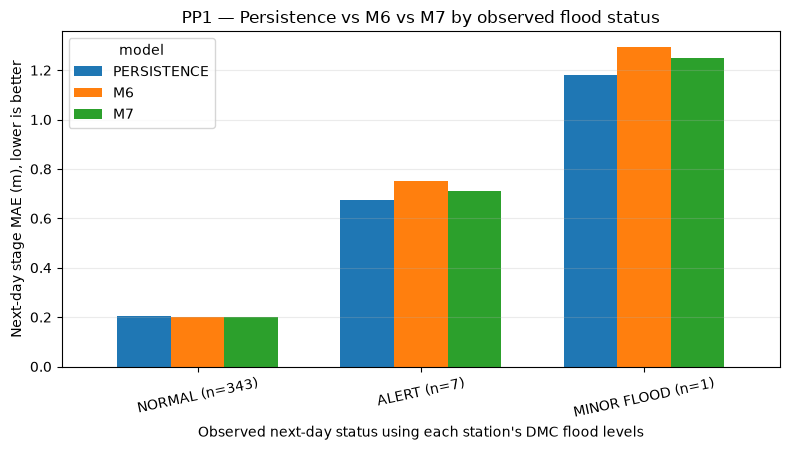

Sample sizes are extremely small for ALERT and MINOR FLOOD; MAJOR FLOOD n=0.


In [10]:
# PP1 Figure B — MAE by OBSERVED gauge-specific flood-status category
# Omit unsupported empty categories (no major flood in the TEST set).
if frames and {'M6','M7'}.issubset(frames):
    selected=flood_status_metrics.loc[flood_status_metrics.model.isin(['PERSISTENCE','M6','M7'])]
    cat_counts=selected.loc[selected.model=='PERSISTENCE'].set_index('observed_status')['n']
    categories=[status for status in STATUS_ORDER if cat_counts.get(status,0)>0]
    means=selected.pivot(index='observed_status',columns='model',values='mae_m').reindex(categories)
    ax=means[['PERSISTENCE','M6','M7']].plot(kind='bar',figsize=(8,4.6),width=.72)
    ax.set_xticklabels([f'{status} (n={int(cat_counts[status])})' for status in categories],rotation=12)
    ax.set_ylabel('Next-day stage MAE (m), lower is better')
    ax.set_xlabel("Observed next-day status using each station's DMC flood levels")
    ax.set_title('PP1 — Persistence vs M6 vs M7 by observed flood status')
    ax.grid(axis='y',alpha=.25)
    fig=ax.get_figure();fig.tight_layout()
    fig.savefig(OUT/'c4_M6_M7_vs_persistence_by_gauge_flood_status.png',dpi=160)
    plt.show()
    print('Sample sizes are extremely small for ALERT and MINOR FLOOD; MAJOR FLOOD n=0.')
else:
    print('M6/M7 prediction files unavailable: figure skipped.')

## C — Per-station improvement over persistence, with alert-context counts

Keep the original **per-gauge MAE and RMSE** comparison. Additionally count observed **Day T+1** instances at/above that *gauge's own* alert level; for each model count missed alerts and false alarms. Thresholds are used **only for evaluating the test predictions**, never as inputs to M1–M7. A gauge with no test alert crossings has **undefined per-station alert recall**, not 100% recall.

In [11]:
# C — Per-station model/persistence error, plus gauge-specific alert detections
if not frames:
    print('No completed model predictions: per-station diagnostic skipped.')
else:
    station_summary=[]
    for model_name,one in status_frames.items():
        if model_name=='PERSISTENCE':continue
        for sid,g in one.groupby('station_id',sort=True):
            e=(g.pred_stage_m-g.target_stage_m).to_numpy()
            baseline=(g.current_stage_m-g.target_stage_m).to_numpy()
            observed=g.target_stage_m.to_numpy()>=g.alert_threshold_m.to_numpy()
            predicted=g.pred_stage_m.to_numpy()>=g.alert_threshold_m.to_numpy()
            mae=float(np.abs(e).mean());base_mae=float(np.abs(baseline).mean())
            station_summary.append({'model':model_name,'station_id':sid,'n':len(g),
                 'model_mae_m':mae,'persistence_mae_m':base_mae,
                 'improvement_over_persistence_m':base_mae-mae,
                 'model_rmse_m':float(np.sqrt(np.mean(e*e))),
                 'persistence_rmse_m':float(np.sqrt(np.mean(baseline*baseline))),
                 'observed_at_or_above_alert_n':int(observed.sum()),
                 'missed_alert_n':int((observed & ~predicted).sum()),
                 'false_alert_n':int((~observed & predicted).sum())})
    station_vs_baseline=pd.DataFrame(station_summary)
    station_vs_baseline.to_csv(PRIVATE_OUT/'c4_station_vs_persistence_PRIVATE.csv',index=False)
    coverage=(station_vs_baseline.assign(improved=lambda d:d.improvement_over_persistence_m>0)
       .groupby('model').agg(stations_tested=('station_id','nunique'),
          stations_better_than_persistence=('improved','sum'),
          total_station_day_rows=('n','sum'),
          observed_at_or_above_alert=('observed_at_or_above_alert_n','sum'),
          missed_alert_n=('missed_alert_n','sum')).reset_index())
    coverage.to_csv(PRIVATE_OUT/'c4_stations_improved_summary_PRIVATE.csv',index=False)
    display(coverage)
    if 'M7' in status_frames:
        print('M7 — 12 gauges with least improvement over persistence:')
        display(station_vs_baseline.loc[station_vs_baseline.model=='M7']
               .sort_values('improvement_over_persistence_m').head(12))
    print('Station-level outputs saved only to:',PRIVATE_OUT)
    print('A 0-alert test station has no observed positive events; do not infer high alert recall.')

,model,stations_tested,stations_better_than_persistence,total_station_day_rows,observed_at_or_above_alert,missed_alert_n
0,M1,39,23,351,8,4
1,M2,39,16,351,8,4
2,M3,39,29,351,8,4
3,M4,39,22,351,8,4
4,M5,39,23,351,8,4
5,M6,39,28,351,8,4
6,M7,39,26,351,8,4


M7 — 12 gauges with least improvement over persistence:


,model,station_id,n,model_mae_m,persistence_mae_m,improvement_over_persistence_m,model_rmse_m,persistence_rmse_m,observed_at_or_above_alert_n,missed_alert_n,false_alert_n
241,M7,glencourse,9,0.168386,0.097778,-0.070608,0.196281,0.117473,0,0,0
238,M7,ellagawa,9,0.339327,0.313333,-0.025993,0.461020,0.426771,0,0,0
247,M7,kithulgala,9,0.127143,0.102222,-0.024921,0.148005,0.139124,0,0,0
236,M7,deraniyagala,9,0.077089,0.056667,-0.020422,0.098318,0.093155,0,0,0
245,M7,kalawellawa_millakanda,9,0.436309,0.417778,-0.018532,0.557649,0.542771,0,0,0
268,M7,thawalama,9,0.368499,0.352222,-0.016277,0.470625,0.465821,0,0,0
270,M7,wellawaya,9,0.040180,0.030000,-0.010180,0.055409,0.043333,0,0,0
246,M7,katharagama,9,0.061194,0.053333,-0.007861,0.078992,0.067165,0,0,0
271,M7,weraganthota,9,0.586462,0.580000,-0.006462,0.929057,0.937550,0,0,0
243,M7,holombuwa,9,0.037767,0.032222,-0.005544,0.044875,0.037268,0,0,0


Station-level outputs saved only to: C:\Users\ASUS\projects\rp_project\J26-DS-314\data\processed\c4\evaluation_private
A 0-alert test station has no observed positive events; do not infer high alert recall.


## D — Glencourse mosaic temporal-integrity audit

This read-only check confirms that the **21 indexed** recovered samples reference only the three known mosaics and were assigned a recorded SAR acquisition earlier than the 09:00 SLST forecast origin. When the original Notebook 02 mosaic QA file is present, a stricter **both-slices-before-origin** check uses the provenance of **each source slice**. Coverage is a different question from temporal integrity.

In [8]:
# D — Verify indexed 21 recovered rows and BOTH source-slice times when metadata exists
mos=aligned[aligned.patch_relpath.astype(str).str.contains('/mosaics/',regex=False)].copy()
assert len(mos)==21, f'Expected exactly 21 mosaic-recovered records; found {len(mos)}'
assert set(mos.station_id)=={'glencourse'} and mos.sar_scene_id.nunique()==3
origin=pd.to_datetime(mos.forecast_date,utc=True)+pd.Timedelta(hours=3,minutes=30)
primary=pd.to_datetime(mos.sar_acquisition_utc,utc=True)
assert (primary<origin).all(),'A mosaic earliest acquisition is not before its forecast origin.'
qa_path=(ROOT/'data/processed/c4/satellite/sentinel1/glencourse_mosaic_extension/'
   'c4_s1_glencourse_mosaic_QA_PRIVATE.csv')
if qa_path.is_file():
    recovery=pd.read_csv(qa_path)
    assert len(recovery)==21 and recovery.record_id.is_unique
    merged=mos.merge(recovery[['record_id','proposed_mosaic_id','earliest_source_utc',
        'latest_source_utc','source_scene_id_1','source_scene_id_2','pixel_valid_union_fraction','recovered']],
        on='record_id',validate='one_to_one')
    assert (merged.sar_scene_id.astype(str)==merged.proposed_mosaic_id.astype(str)).all()
    assert merged.recovered.astype(bool).all()
    first=pd.to_datetime(merged.earliest_source_utc,utc=True)
    last=pd.to_datetime(merged.latest_source_utc,utc=True)
    cutoff=pd.to_datetime(merged.forecast_date,utc=True)+pd.Timedelta(hours=3,minutes=30)
    assert (first<=last).all() and (last<cutoff).all(), 'Mosaic has a future source slice.'
    assert (merged.pixel_valid_union_fraction>.97).all()
    merged[['record_id','forecast_date','proposed_mosaic_id','earliest_source_utc',
      'latest_source_utc','pixel_valid_union_fraction']].to_csv(OUT/'c4_glencourse_21_temporal_QA.csv',index=False)
    print('PASS: 21 Glencourse rows, 3 same-pass mosaics, BOTH source slices before all 21 forecast origins.')
    display(merged.groupby('proposed_mosaic_id').agg(n=('record_id','count'),
       earliest_forecast_date=('forecast_date','min'),last_forecast_date=('forecast_date','max'),
       union_fraction_min=('pixel_valid_union_fraction','min')).reset_index())
else:
    print('PARTIAL PASS: all 21 indexed earliest acquisitions predate the origins.')
    print('To verify both slice times, provide original Notebook 02 QA:',qa_path)

PASS: 21 Glencourse rows, 3 same-pass mosaics, BOTH source slices before all 21 forecast origins.


,proposed_mosaic_id,n,earliest_forecast_date,last_forecast_date,union_fraction_min
0,GLEN_S1_20251114_ABS61866,9,2025-11-17,2025-11-25,0.999924
1,GLEN_S1_20251126_ABS62041,6,2025-11-26,2025-12-01,0.999908
2,GLEN_S1_20251220_ABS62391,6,2025-12-20,2025-12-25,0.999939


### PP1 reporting checklist

- **Completed prototype:** 40 candidate catchments, 39 labelled gauges, 1,429 aligned station-days, and seven model configurations (provided all seven prediction CSVs exist).
- **Model performance:** Compare all seven MAE/RMSE values with persistence and report M7 versus M6. Large differences in the observed stage-change distributions across dates make pooled error alone insufficient.
- **Gauge-specific warning levels:** Official source-derived alert, minor-flood and major-flood thresholds belong to **individual gauges**, are evaluated against next-day observed and predicted *absolute stage*, and are NOT used as neural-network training inputs. Test counts: **343 NORMAL, 7 ALERT, 1 MINOR FLOOD, 0 MAJOR FLOOD**; no major-flood recall can be measured.
- **Mosaic timing:** The three Glencourse mosaics recover 21 station-days. Their spatial union coverage fractions of ~0.9999 indicate valid *pixel coverage*, not hydrological accuracy. The two-source-slice temporal QA must pass for all 21 origin times.
- **Forecast realism:** This is a 09:00 retrospective hindcast; original DMC report publication was nominally 09:30, and reanalysis products are not proven to have been operationally available by the simulated origin.
- **Next step:** Additional historically distinct flood episodes and gauge data are necessary before estimating major-flood forecasting ability or operational deployment suitability.